**Segmentasi Citra Berbasis Similaritas**

---

### 1. Konsep Segmentasi Berbasis Similaritas

Segmentasi berbasis similaritas mengelompokkan piksel-piksel yang memiliki kesamaan nilai intensitas, tekstur, atau atribut lainnya. Pendekatan ini berfokus pada keseragaman lokal atau global dalam citra untuk memisahkan objek dari latar belakang.

Metode populer:

* *Global Thresholding*
* *Otsu’s Method*
* *Optimal Thresholding Iteratif*
* *Adaptive Thresholding*
* *Histogram of Gradient (HoG)*

---

### 2. Global Thresholding

#### Konsep:

Global thresholding membagi piksel menjadi dua kelompok (foreground/objek dan background/latar belakang) berdasarkan nilai ambang (threshold) tetap.

#### Implementasi:


libpng warning: iCCP: extra compressed data


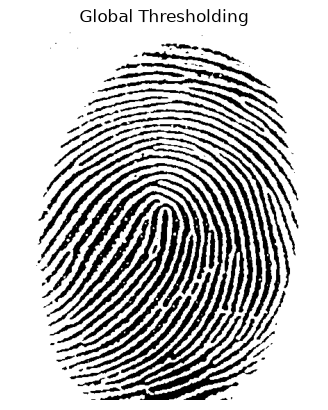

In [2]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('image_global_thresholding.png', 0)
_, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

plt.imshow(thresh, cmap='gray')
plt.title('Global Thresholding')
plt.axis('off')
plt.show()


#### Eksperimen:


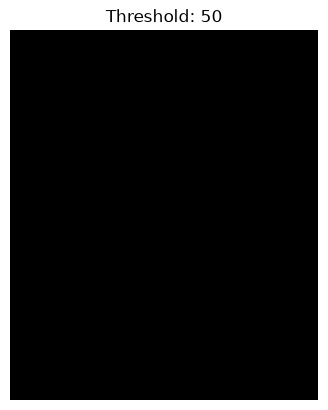

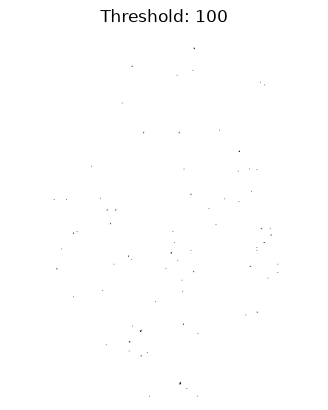

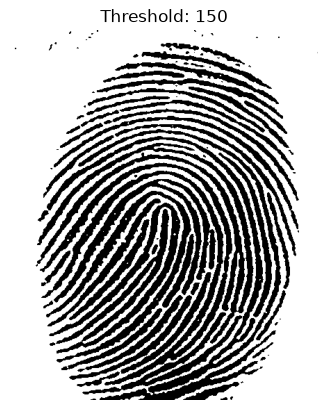

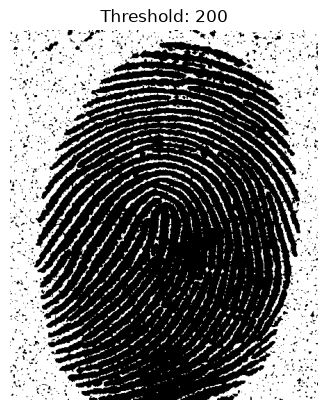

In [3]:
for t in [50, 100, 150, 200]:
    _, th = cv2.threshold(img, t, 255, cv2.THRESH_BINARY)
    plt.figure(), plt.imshow(th, cmap='gray')
    plt.title(f'Threshold: {t}'), plt.axis('off')


---

### 3. Otsu’s Method

#### Konsep:

Otsu mencari ambang optimal dengan meminimalkan variansi intra-kelas.

#### Implementasi:


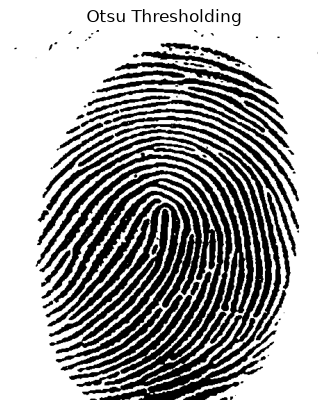

In [4]:
_, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(otsu, cmap='gray')
plt.title('Otsu Thresholding')
plt.axis('off')
plt.show()


#### Visualisasi Histogram:


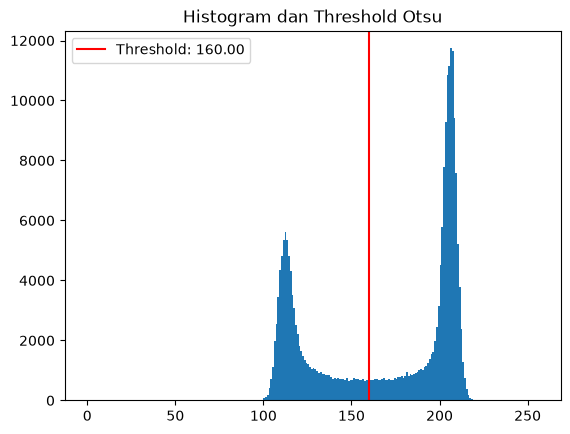

In [5]:
plt.hist(img.ravel(), bins=256, range=[0,256])
plt.axvline(_, color='r', label=f'Threshold: {_:.2f}')
plt.title('Histogram dan Threshold Otsu')
plt.legend()
plt.show()


---

### 4. Optimal Thresholding (Iteratif)

#### Konsep:

1. Tentukan threshold awal (misal rata-rata intensitas)
2. Kelompokkan piksel menjadi dua berdasarkan threshold
3. Hitung rata-rata masing-masing kelompok
4. Update threshold sebagai rata-rata dari dua nilai rata-rata tersebut
5. Ulangi hingga konvergen

#### Implementasi:


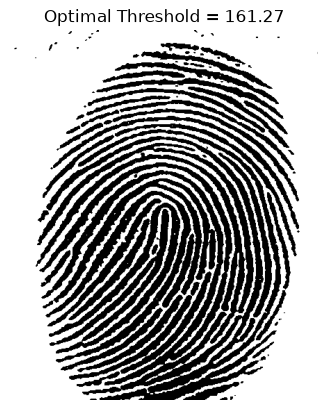

In [6]:
def optimal_threshold(img):
    T = img.mean()
    while True:
        G1 = img[img > T]
        G2 = img[img <= T]
        new_T = (G1.mean() + G2.mean()) / 2
        if abs(T - new_T) < 1:
            break
        T = new_T
    return T

T = optimal_threshold(img)
ret, opt_thresh = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)
plt.imshow(opt_thresh, cmap='gray')
plt.title(f'Optimal Threshold = {T:.2f}')
plt.axis('off')
plt.show()


---

### 5. Adaptive Thresholding

#### Konsep:

* Menentukan threshold untuk tiap piksel berdasarkan lingkungan lokal (blok kecil).
* Menggunakan ambang lokal berdasarkan rata-rata atau Gaussian dari lingkungan sekitar setiap piksel.

#### Implementasi:


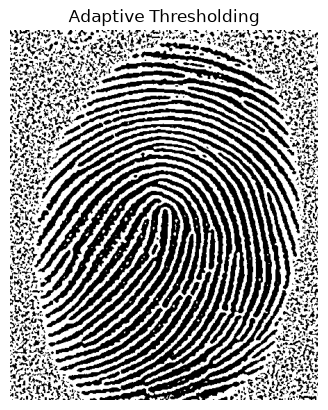

In [7]:
adaptive = cv2.adaptiveThreshold(img, 255,
                                 cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, 11, 2)
plt.imshow(adaptive, cmap='gray')
plt.title('Adaptive Thresholding')
plt.axis('off')
plt.show()


#### Eksperimen Blok Ukuran:


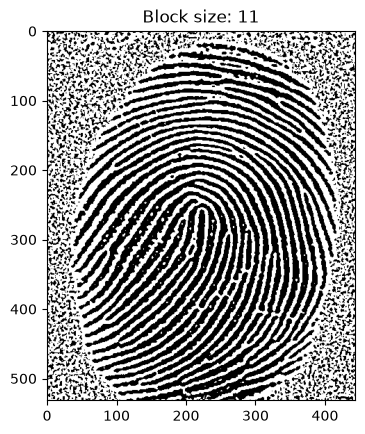

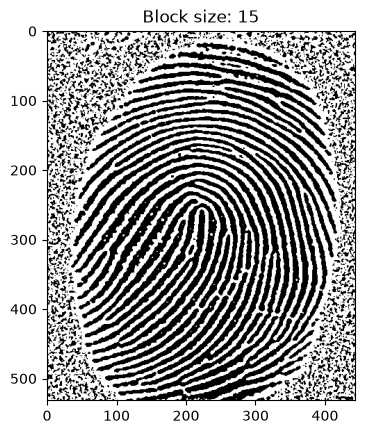

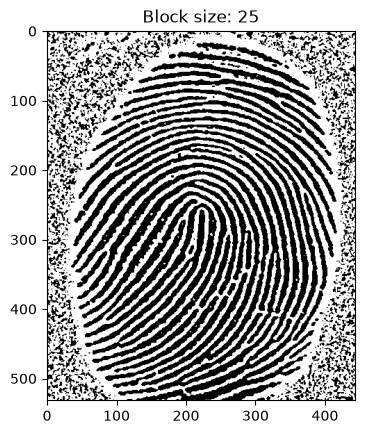

In [8]:
for block_size in [11, 15, 25]:
    adaptive = cv2.adaptiveThreshold(img, 255,
                                     cv2.ADAPTIVE_THRESH_MEAN_C,
                                     cv2.THRESH_BINARY, block_size, 2)
    plt.figure(), plt.imshow(adaptive, cmap='gray')
    plt.title(f'Block size: {block_size}')


---

### 6. Histogram of Oriented Gradient (HoG)

#### Konsep:

* Ekstraksi fitur tepi dan orientasi gradien pada blok-blok kecil citra (lokal).
* Digunakan untuk deteksi objek dan segmentasi berbasis fitur.

#### Implementasi (Visualisasi HoG):


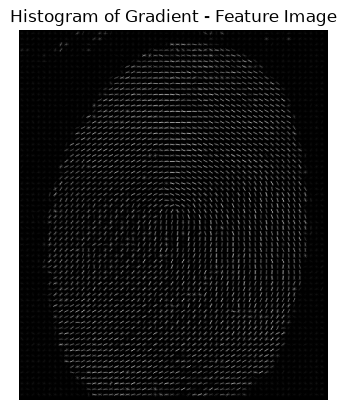

In [10]:
from skimage.feature import hog
from skimage import exposure

# Hitung HOG
fd, hog_image = hog(img, orientations=9, pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2), visualize=True)

plt.imshow(hog_image, cmap='gray')
plt.title('Histogram of Gradient - Feature Image')
plt.axis('off')
plt.show()


#### Eksperimen:


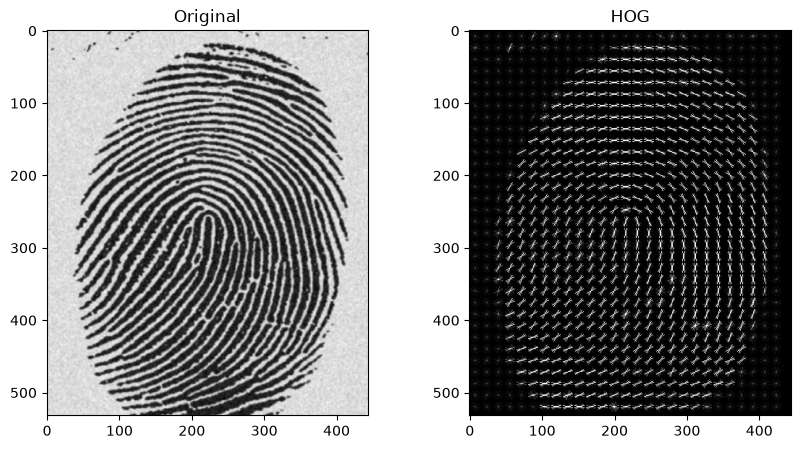

In [11]:
# Hitung HOG
fd, hog_image = hog(img, orientations=8, pixels_per_cell=(16, 16),
                    cells_per_block=(1, 1), visualize=True)

# Rescale HOG untuk visualisasi
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(122), plt.imshow(hog_image_rescaled, cmap='gray'), plt.title('HOG')
plt.show()


---

### 7. Integrasi dengan Penyambungan Tepi

Thresholding dapat dikombinasikan dengan penyambungan tepi untuk menyaring hasil tepi:


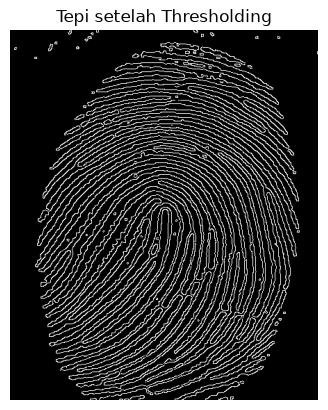

In [12]:
edges = cv2.Canny(img, 100, 200)
masked = cv2.bitwise_and(edges, edges, mask=thresh)
plt.imshow(masked, cmap='gray')
plt.title('Tepi setelah Thresholding')
plt.axis('off')
plt.show()


---

### 8. Kesimpulan

* Segmentasi berbasis similaritas efektif untuk memisahkan objek dengan intensitas homogen.
* Global thresholding cepat namun tidak fleksibel, cocok untuk citra dengan kontras tinggi.
* Metode Otsu, optimal thresholding, dan adaptive thresholding memberikan hasil otomatis, sehingga lebih fleksibel untuk kondisi pencahayaan tidak merata.
* HoG membuka jalan menuju segmentasi berbasis pembelajaran fitur (feature-based segmentation).
* Eksperimen parameter seperti ambang batas dan ukuran blok menunjukkan sensitivitas metode terhadap variasi input.
* Integrasi dengan metode seperti deteksi tepi dapat meningkatkan kualitas segmentasi akhir.


---

### 9. Eksperimen Tambahan 

1. **Multilevel Thresholding (Multiple Thresholds)** : Membagi citra ke dalam beberapa kelas intensitas (misal: background, intensitas sedang, dan intensitas tinggi) dengan menggunakan lebih dari satu nilai ambang ($T_1, T_2$).  

2. **Uji Ketahanan terhadap Iluminasi Tidak Rata (*Spot Shading / Non-Uniform Illumination*)**: Menguji dan membandingkan kegagalan metode global (*Global Thresholding* dan *Otsu*) dibandingkan keberhasilan *Locally Adaptive Thresholding* pada kondisi pencahayaan yang tidak seragam.  

3. **Thresholding dengan Seleksi Karakteristik Batas Gradien (*Boundary-Selected Thresholding*)**: Memanfaatkan informasi gradien (Sobel) untuk menyeleksi hanya piksel-piksel di sekitar batas objek, sehingga menghasilkan histogram bimodal yang tajam dan nilai threshold yang jauh lebih akurat meskipun background mendominasi.


#### 9.1 Multilevel Thresholding (Multiple Thresholds - Slide 3)

Pada kasus citra yang memiliki objek dengan beberapa tingkat keabuan berbeda, ambang tunggal tidak cukup. Algoritma mempartisi rentang intensitas menjadi 3 kelas menggunakan dua ambang batas ($T_1, T_2$):
$$
g(x, y) = 
\begin{cases} 
0, & f(x, y) \le T_1 \\ 
128, & T_1 < f(x, y) \le T_2 \\ 
255, & f(x, y) > T_2 
\end{cases}
$$


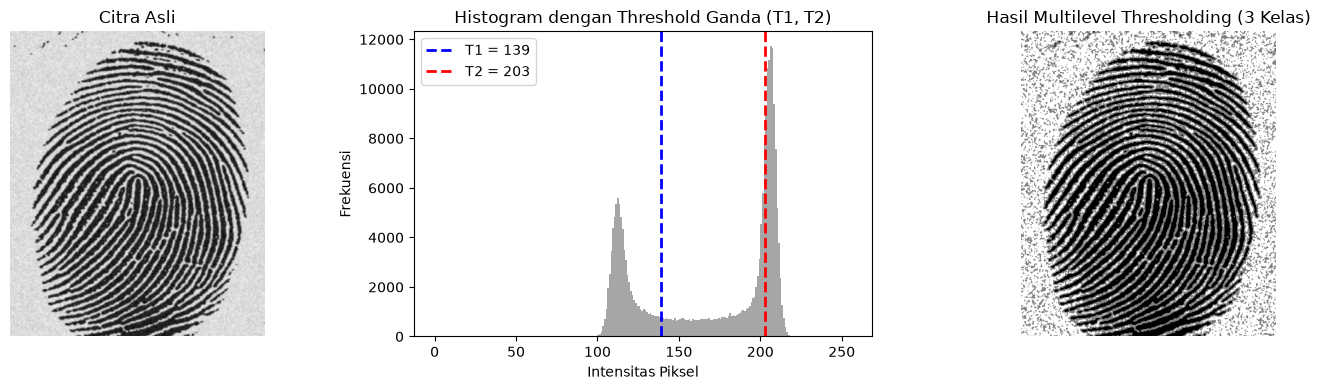

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Hitung histogram kumulatif untuk menentukan threshold T1 dan T2
hist, bins = np.histogram(img.ravel(), 256, [0, 256])
cdf = hist.cumsum() / hist.sum()

# Menentukan ambang batas T1 dan T2 (berdasarkan persentil 33% dan 66%)
T1 = int(np.searchsorted(cdf, 0.33))
T2 = int(np.searchsorted(cdf, 0.66))

# 2. Segmentasi Multilevel (3 Tingkat)
multi_thresh = np.zeros_like(img, dtype=np.uint8)
multi_thresh[(img > T1) & (img <= T2)] = 128
multi_thresh[img > T2] = 255

# 3. Visualisasi
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray', alpha=0.7)
plt.axvline(T1, color='blue', linestyle='--', linewidth=2, label=f'T1 = {T1}')
plt.axvline(T2, color='red', linestyle='--', linewidth=2, label=f'T2 = {T2}')
plt.title('Histogram dengan Threshold Ganda (T1, T2)')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Frekuensi')
plt.legend()

plt.subplot(1, 3, 3)
plt.imshow(multi_thresh, cmap='gray')
plt.title('Hasil Multilevel Thresholding (3 Kelas)')
plt.axis('off')
plt.tight_layout()
plt.show()


#### 9.2 Segmentasi pada Iluminasi Tidak Rata (*Spot Shading*)

Pada dunia nyata, citra dokumen atau objek sering kali memiliki pencahayaan tidak merata (misalnya akibat bayangan atau lampu sorot/spotlight). Metode global (*Global tetap* dan *Otsu*) akan mengalami degradasi performa yang signifikan, sementara *Locally Adaptive Thresholding* mampu mempertahankan kontur objek secara utuh.


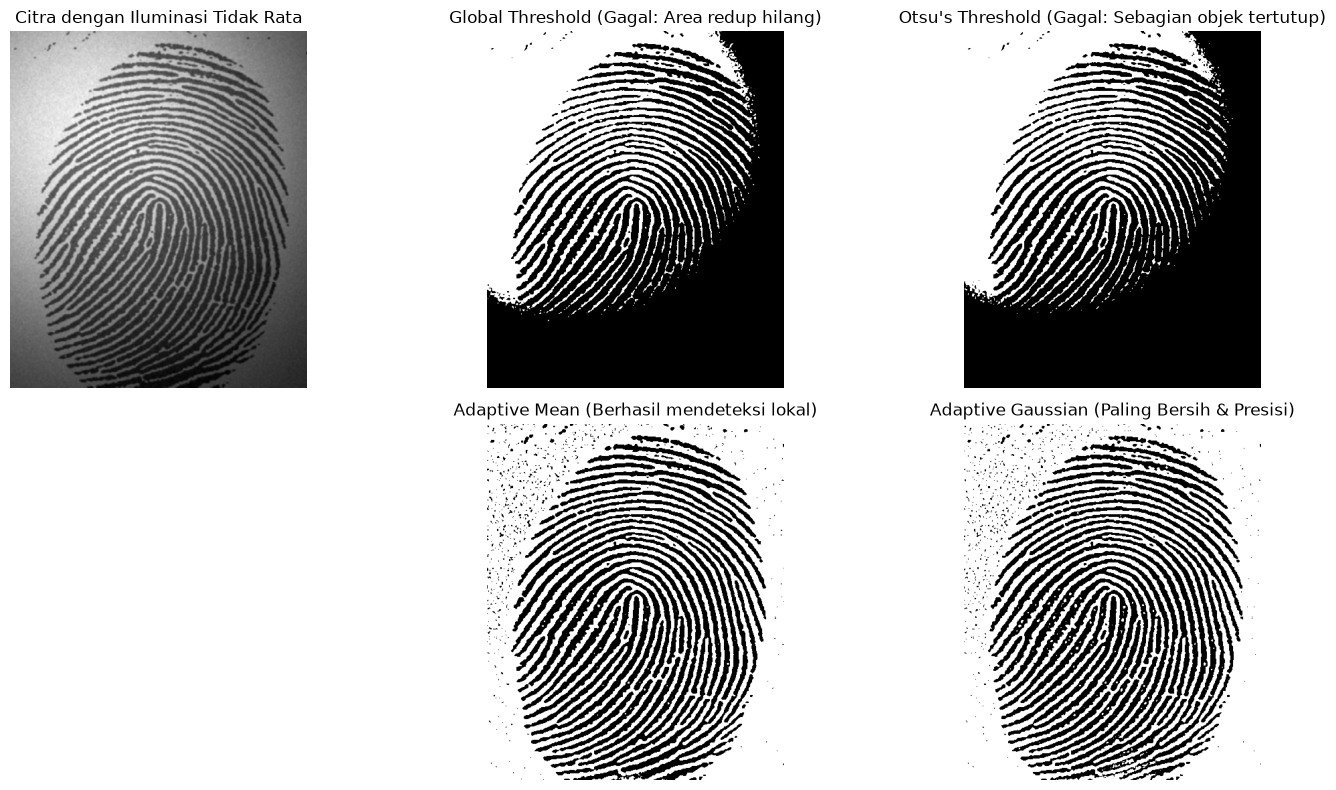

In [17]:
# 1. Simulasi degradasi iluminasi tidak merata (spot shading / vignetting)
h, w = img.shape
Y, X = np.ogrid[:h, :w]
spot_center_x, spot_center_y = w * 0.3, h * 0.3
spot_radius = min(h, w) * 0.5
spot_light = np.exp(-((X - spot_center_x)**2 + (Y - spot_center_y)**2) / (2 * spot_radius**2))
spot_shading = 0.25 + 0.75 * spot_light
img_shaded = np.clip(img.astype(np.float32) * spot_shading, 0, 255).astype(np.uint8)

# 2. Uji berbagai metode segmentasi
_, th_global = cv2.threshold(img_shaded, 127, 255, cv2.THRESH_BINARY)
_, th_otsu = cv2.threshold(img_shaded, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
th_adapt_mean = cv2.adaptiveThreshold(img_shaded, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 21, 5)
th_adapt_gauss = cv2.adaptiveThreshold(img_shaded, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 5)

# 3. Visualisasi perbandingan
plt.figure(figsize=(15, 8))
plt.subplot(2, 3, 1)
plt.imshow(img_shaded, cmap='gray')
plt.title('Citra dengan Iluminasi Tidak Rata')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(th_global, cmap='gray')
plt.title('Global Threshold (Gagal: Area redup hilang)')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(th_otsu, cmap='gray')
plt.title("Otsu's Threshold (Gagal: Sebagian objek tertutup)")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(th_adapt_mean, cmap='gray')
plt.title('Adaptive Mean (Berhasil mendeteksi lokal)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(th_adapt_gauss, cmap='gray')
plt.title('Adaptive Gaussian (Paling Bersih & Presisi)')
plt.axis('off')

plt.tight_layout()
plt.show()


#### 9.3 Thresholding Menggunakan Karakteristik Batas Gradien (*Boundary-Selected Thresholding*)

Ketika latar belakang sangat dominan atau citra memiliki noise, histogram keseluruhan citra menjadi tidak bimodal (*unbalanced*).

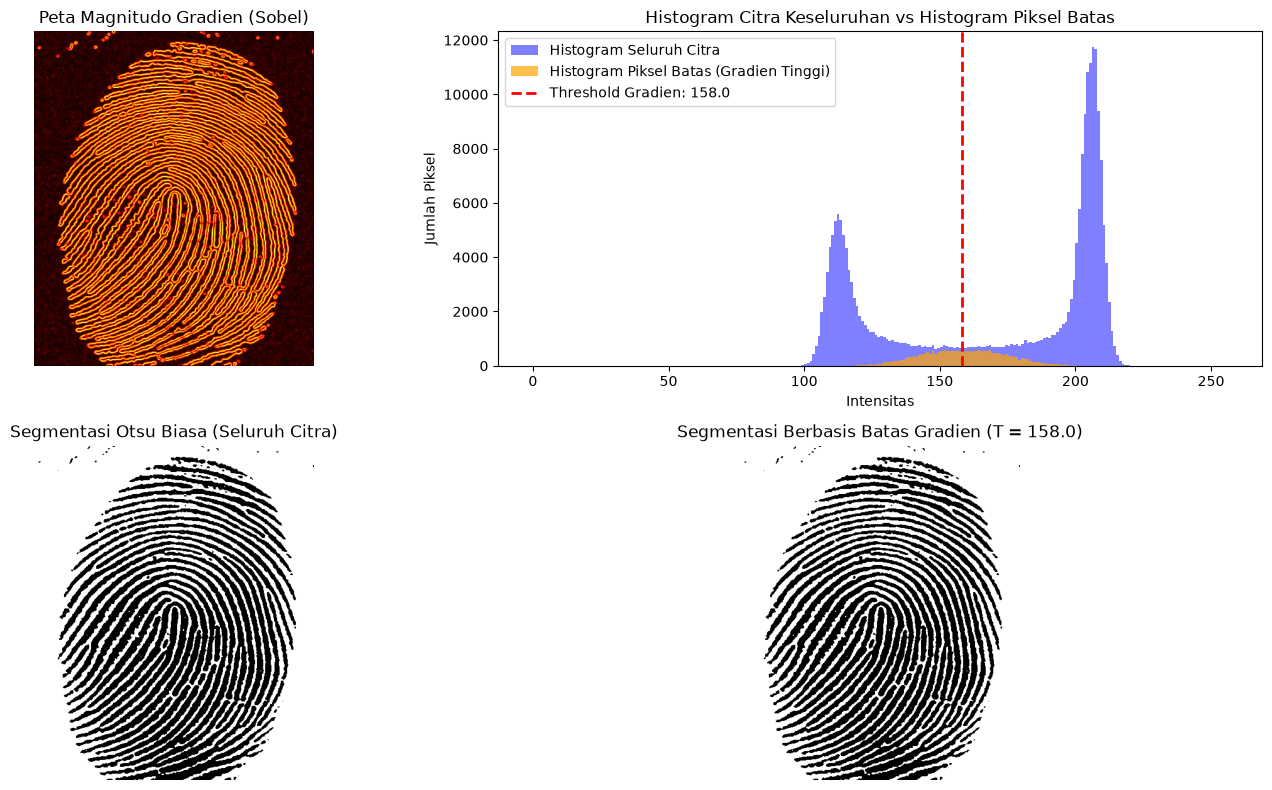

In [19]:
# 1. Hitung magnitudo gradien menggunakan operator Sobel
grad_x = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
grad_y = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
magnitude = cv2.magnitude(grad_x, grad_y)

# 2. Seleksi piksel batas: ambil 10% piksel dengan gradien tertinggi (persentil ke-90)
grad_threshold = np.percentile(magnitude, 90)
edge_mask = magnitude > grad_threshold
boundary_pixels = img[edge_mask]

# 3. Hitung threshold optimal hanya dari piksel batas tersebut
t_boundary, _ = cv2.threshold(boundary_pixels, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 4. Terapkan threshold hasil boundary ke seluruh citra
_, seg_boundary = cv2.threshold(img, int(t_boundary), 255, cv2.THRESH_BINARY)
_, seg_std_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 5. Visualisasi perbandingan
plt.figure(figsize=(15, 8))
plt.subplot(2, 2, 1)
plt.imshow(magnitude, cmap='hot')
plt.title('Peta Magnitudo Gradien (Sobel)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.hist(img.ravel(), bins=256, range=[0, 256], alpha=0.5, label='Histogram Seluruh Citra', color='blue')
plt.hist(boundary_pixels, bins=256, range=[0, 256], alpha=0.7, label='Histogram Piksel Batas (Gradien Tinggi)', color='orange')
plt.axvline(t_boundary, color='red', linestyle='--', linewidth=2, label=f'Threshold Gradien: {t_boundary:.1f}')
plt.title('Histogram Citra Keseluruhan vs Histogram Piksel Batas')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')
plt.legend()

plt.subplot(2, 2, 3)
plt.imshow(seg_std_otsu, cmap='gray')
plt.title('Segmentasi Otsu Biasa (Seluruh Citra)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(seg_boundary, cmap='gray')
plt.title(f'Segmentasi Berbasis Batas Gradien (T = {t_boundary:.1f})')
plt.axis('off')

plt.tight_layout()
plt.show()


#### Analisis Eksperimen Tambahan:

1. **Multilevel Thresholding**: Berhasil memisahkan citra menjadi 3 kelas berbeda tanpa kehilangan wilayah abu-abu peralihan (*mid-tones*), sangat bermanfaat jika objek memiliki lebih dari satu komponen reflektansi.  

2. **Ketahanan Iluminasi Tidak Rata**: Secara nyata memperlihatkan kegagalan metode *Global* dan *Otsu* pada citra terdegradasi bayangan (*spot shading*), sementara *Adaptive Gaussian* mampu mengekstrak batas lokal dengan presisi tinggi tanpa terpengaruh perbedaan terang-gelap global.  

3. **Thresholding Berbasis Batas Gradien**: Mengatasi kelemahan histogram global yang didominasi oleh area background luas dengan menyaring hanya piksel-piksel transisi batas, menghasilkan penentuan threshold yang kokoh (*robust*) terhadap variasi proporsi ukuran objek.
